# INTRODUCTION

## Domain-Specific Area: Finding Fake News

A serious and challenging problem in the area of Natural Language Processing (NLP) is fake news detection, which is about automatically figuring out if a news article has truthful or misleading information. Digital news sites and social media have grown very quickly, which has made information spread much more quickly. This makes it harder for people who check facts to keep up with all the content. Due to this, automated methods that can help find possibly false information have become an important area of research and application (S. Kuntur, 2024), (Patel, 2024).

In In terms of technology, fake news detection is usually set up as a supervised text classification job (R. Oshikawa, 2020), (govt, 2025). In this, models are trained on labeled examples of news articles and learn to tell the difference between real and fake content. Natural language processing works especially well on this kind of problem because it involves analyzing a lot of text that isn’t organized in a neat format. In the beginning, methods for spotting fake news focused on surfacelevel features like the number of times words appeared, stylistic cues, and simple lexical patterns. These methods are quick and easy to understand, but they often have trouble with deeper meaning and connections in the text (R. Oshikawa, 2020), (Halyna Padalko, 2024).

More modern methods use statistical weighting schemes and neural representations to do a better job. Statistical models like TF-IDF with linear classifiers try to make the effect of common words smaller and the effect of useful words bigger. Neural models, especially those that use word embeddings and recurrent structures, learn even more by learning about the patterns that happen in context and over time. This lets them figure out how meaning changes throughout a sentence or document (al., 2025), (N. M. Alkudah, 2025), (Halyna Padalko, 2024). Following this move from simple to complicated models, all three models in this project are tested with the same dataset and evaluation framework: a Bag-of-Words baseline, a TF-IDF statistical model, and a Bidirectional LSTM embedding-based model.

It is still difficult to tell fake news apart from real news, even though modeling methods have come a long way. People write in many different ways, misinformation can be sneaky instead of obviously lying, and models might pick up dataset-specific artifacts instead of patterns that apply to all datasets (S. Kuntur, 2024), (Sun, 2025). These problems show that it’s better to use thorough model comparison instead of just one method (Patel, 2024), (govt, 2025). This project is about the domain of fake news detection. It does this by gradually making the models more complicated and looking at how different NLP representations change the performance of the classification, the patterns of mistakes, and the behavior of generalization.

## Objectives of the Project

The main goal of this project is to build, test, and review a number of NLP-based classification models for finding fake news. The focus will be on finding differences in how well the models do, rather than just looking at how well each one does on its own. The project is set up to show how applying different ways of writing and modeling to the same dataset in controlled settings affects the classification results (R. Oshikawa, 2020), (Patel, 2024).

The first goal is to set up a basic model with a Bag-of-Words representation and a Multinomial Naive Bayes classifier. In this method, the CountVectorizer with a fixed maximum vocabulary size and minimal preprocessing through the basic_clean function are used. The standard shows the minimum level of performance and gives a way to measure how much better more advanced models are (Patel, 2024), (govt, 2025).

The second goal is to use TF-IDF traits and logistic regression to build a statistical classification model. The clean_for_tfidf function adds extra preparation to this model. This function gets rid of short tokens and stopwords and uses TF-IDF weighting with both unigrams and bigrams. Using logistic regression with class balancing is meant to make the results more reliable and show how statistical feature selection can work much better than simple frequency-based methods (al., 2025), (Halyna Padalko, 2024), (govt, 2025).

The third goal is to look into an embedding-based deep learning approach with a Bidirectional LSTM. Using a Keras Tokenizer, this model turns text into padded sequences. It also has an embedding layer and a recurrent structure that keeps word order and contextual relationships. Early stopping and confirmation splits are used to deal with overfitting, which is something that should be thought about when training neural networks (N. M. Alkudah, 2025), (Halyna Padalko, 2024).

Finally, the project’s main goal is to use the same way of testing on all models. The project hopes to give useful information about the pros and cons of simplicity, understandability, cost, and predictive performance in the test and train splits, common evaluation metrics, and confusion matrix pictures. The project doesn’t try to find the “best” model. Instead, it shows how different models work and where each one might work best in real-life fake news spotting situations (R. Oshikawa, 2020), (Patel, 2024), (Rohini Jadhav, 2025).

In [1]:
pip install -U scikit-learn

# Let's import all the libraries

In [1]:
pip install tensorflow

In [1]:
# Basic Python libraries for file handling, text processing, and saving models
import os
import re
import pickle

# Data science libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Natural Language Processing (NLP) libraries
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Machine Learning libraries from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Deep Learning libraries (TensorFlow/Keras)
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


# Here we define all the settings and hyperparameters for our models

In [2]:
# General settings
SEED = 42
DATA_PATH = "dataset/fake_train.csv"

# TF-IDF model settings (Model 2)
TFIDF_MAX_FEATURES = 50000
TFIDF_NGRAMS = (1, 2)

# Baseline BoW settings (Model 1)
BOW_MAX_FEATURES = 20000

# Embedding model settings (Model 3 - Neural Network)
MAX_WORDS = 30000
MAX_LEN = 250
EMBED_DIM = 128
LSTM_UNITS = 64
EPOCHS = 6
BATCH_SIZE = 64

print("Configuration settings loaded:")
print(f"- Random seed: {SEED}")
print(f"- Data path: {DATA_PATH}")
print(f"- TF-IDF max features: {TFIDF_MAX_FEATURES}")
print(f"- BoW max features: {BOW_MAX_FEATURES}")
print(f"- Embedding dimensions: {EMBED_DIM}")
print(f"- LSTM units: {LSTM_UNITS}")

Configuration settings loaded:
- Random seed: 42
- Data path: dataset/fake_train.csv
- TF-IDF max features: 50000
- BoW max features: 20000
- Embedding dimensions: 128
- LSTM units: 64


## Description of the Selected Dataset

The Fake News Dataset from Kaggle that came with the training is being used for this project. It’s made for binary classification jobs in fake news detection, and it’s made up of news articles with labels that show whether the content is fake or real. The pandas.read_csv method loads the dataset, which is then checked to make sure that the text and label columns are there. The selection of appropriate and well-structured datasets is a critical first step in the modeling pipeline (S. Kuntur, 2024).

There are 20,761 samples in the dataset, and each one has two characteristics. The label attribute is a numeric binary indicator that shows 0 for fake news and 1 for real news, and the text attribute has unstructured natural language text that comes from the news story. The dataset is very well balanced, with 10,374 real articles and 10,387 fake ones (chendra, 2020). This was proven by the exploratory output that was printed after the data was loaded. This balance is beneficial because it keeps accuracy as a useful way to measure performance and prevents favoring one class over another (S. Kuntur, 2024), (Sun, 2025).

The text-based info comes in a range of lengths and formats, from short, headline-like bits to longer, article-style sections. Because of this variability, the sample can be used to test both statistical and neural methods. Before modeling, missing values are deleted and labels are directly changed to integer format so that they can be used with scikit-learn classifiers and TensorFlow/Keras models. Only the columns with important information are kept. This reduces noise and keeps the pipeline on task (al., 2025), (N. M. Alkudah, 2025).

The dataset is divided into a “train” set and a “test” set using an 80/20 stratified split, which gives 16,608 samples for training and 4,153 samples for testing. Stratification keeps the class distribution the same in both sets. This is important for a fair comparison of models (Sun, 2025), (Makoto Amakawa, 2025). Overall, this dataset is a great start for the project because it is big enough for deep learning, balanced enough to get rid of false positives, and realistic enough to show how hard it is to find fake news in real-world NLP apps (S. Kuntur, 2024), (Patel, 2024).

# Download stopwords and set random seeds for reproducibility

In [3]:
# Set random seeds so we get the same results each time we run
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Download necessary NLTK data files
nltk.download("punkt")
nltk.download("stopwords")

# Load English stopwords (common words like 'the', 'is', 'and')
STOP_WORDS = set(stopwords.words("english"))

print(f"✓ Reproducibility setup complete (seed: {SEED})")
print(f"✓ NLTK resources downloaded")
print(f"✓ Loaded {len(STOP_WORDS)} stopwords")

[nltk_data] Downloading package punkt to /home/jovyan/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


✓ Reproducibility setup complete (seed: 42)
✓ NLTK resources downloaded
✓ Loaded 198 stopwords


[nltk_data] Downloading package stopwords to /home/jovyan/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


# DATA PREPROCESSING

The dataset was loaded from a CSV file and only the relevant columns (text and label) were kept. Any missing rows were removed to prevent errors during training, and the labels were converted into integer format to ensure compatibility with both scikit-learn and Keras. To make the results reproducible, fixed random seeds were set for NumPy and TensorFlow.

NLTK resources were downloaded for tokenisation and stopword removal, and an English stopword list was created. Two preprocessing pipelines were implemented because different model types benefit from different text preparation. A basic cleaning function was applied across all models, which lowercased the text, removed URLs, stripped non-alphabetic characters, and normalised whitespace to reduce noise while keeping most meaning intact.

For the TF-IDF model, an additional cleaning step tokenised the text, removed stopwords, and filtered out very short tokens, which helps sparse statistical features focus on informative words. Finally, the dataset was split into training and test sets using an 80/20 stratified split to preserve the original label distribution and keep comparisons fair across models.

# These functions will help us clean text, calculate scores, and plot results

In [4]:
def basic_clean(text: str) -> str:
    # Convert to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Keep only letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


def clean_for_tfidf(text: str) -> str:
    # First do basic cleaning
    cleaned = basic_clean(text)

    # Split into individual words
    tokens = word_tokenize(cleaned)

    # Remove stopwords and words shorter than 3 characters
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 2]

    # Join words back into a string
    return " ".join(tokens)


def print_scores(name, y_true, y_pred):
    # Calculate accuracy (percentage of correct predictions)
    acc = accuracy_score(y_true, y_pred)

    # Calculate precision, recall, and F1-score
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )

    # Print results in a nice format
    print("RESULTS:", name)
    print("*" * 39)
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {p:.4f}")
    print(f"Recall   : {r:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))

    # Return results as a dictionary for later comparison
    return {"model": name, "accuracy": acc, "precision": p, "recall": r, "f1": f1}




def plot_conf_matrix(name, y_true, y_pred):
    # Create confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Fake(0)", "Real(1)"])

    # Plot the matrix
    fig, ax = plt.subplots(figsize=(5, 4))
    disp.plot(ax=ax, values_format="d")
    ax.set_title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


def plot_comparison(results_df):
    metrics = ["accuracy", "precision", "recall", "f1"]
    models = results_df["model"].tolist()

    x = np.arange(len(models))
    width = 0.2

    # Create grouped bar chart
    fig, ax = plt.subplots(figsize=(11, 5))
    for i, met in enumerate(metrics):
        ax.bar(x + (i - 1.5) * width, results_df[met].values, width, label=met.capitalize())



    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=15, ha="right")


    ax.set_ylim(0, 1.0)
    ax.set_ylabel("Score")
    ax.set_title("Model Performance Comparison")
    ax.legend()
    plt.tight_layout()
    plt.show()

print("✓ Helper functions that are defined:")
print(" - basic_clean()")
print(" - clean_for_tfidf()")
print(" - print_scores()")
print(" - plot_conf_matrix()")
print(" - plot_comparison()")

✓ Helper functions that are defined:
 - basic_clean()
 - clean_for_tfidf()
 - print_scores()
 - plot_conf_matrix()
 - plot_comparison()


# Load our fake news dataset and check what it looks like

In [5]:
# Check if the file exists
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"File not found: {DATA_PATH}")

# Read the CSV file
df = pd.read_csv(DATA_PATH)

# Make sure we have the required columns
if "text" not in df.columns or "label" not in df.columns:
    raise ValueError(f"CSV must contain 'text' and 'label'. Found: {df.columns.tolist()}")



# Keep only the columns we need and remove any empty rows
df = df[["text", "label"]].dropna()

# Make sure labels are integers (0 or 1)
df["label"] = df["label"].astype(int)

print("DATASET LOADED")
print("*" * 14)
print("Shape:", df.shape)
print("Label distribution:\n", df["label"].value_counts(dropna=False))
print("\nSample rows:\n", df.head())

DATASET LOADED
**************
Shape: (20761, 2)
Label distribution:
 0    10387
1    10374
Name: label, dtype: int64

Sample rows:
                                                 text  label
0  House Dem Aide: We Didn’t Even See Comey’s Let...      1
1  Ever get the feeling your life circles the rou...      0
2  Why the Truth Might Get You Fired October 29, ...      1
3  Videos 15 Civilians Killed In Single US Airstr...      1
4  Print \nAn Iranian woman has been sentenced to...      1


# Split our data: 80% for training, 20% for testing

In [6]:
# Prepare our data
# X = all the news articles (input)
X = df["text"].astype(str).tolist()



# y = all the labels: 0=fake, 1=real (output)
y = df["label"].values

# Split into training and testing sets
# stratify=y ensures both sets have same proportion of fake/real news
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("SPLIT")
print("*" * 5)
print("Train size:", len(X_train_raw))
print("Test size :", len(X_test_raw))

SPLIT
*****
Train size: 16608
Test size : 4153


# Baseline Model - Prepare the Data

A Bag-of-Words representation combined with Multinomial Naive Bayes was selected as the baseline because it is simple, fast, and commonly used as a benchmark in text classification. After applying the basic cleaning, the text was converted into sparse word-count vectors using a limited vocabulary and a minimum document-frequency threshold to remove very rare terms. The Naive Bayes classifier was trained on the training set and evaluated on the test set using accuracy, precision, recall, and F1score. The baseline achieved reasonable performance, showing that word frequency alone captures a meaningful signal for the task, but the confusion matrix still showed a noticeable number of misclassifications, especially in cases where the model likely needed more context than simple word counts can provide. This baseline therefore acts as a clear lower bound against which improvements from more advanced models can be measured.

# Model 1: Bag of Words + Naive Bayes

# Clean the text and convert it to BoW features

In [7]:
print("BASELINE: BoW + Multinomial Naive Bayes")
print("*" * 39)

# Clean all the text (remove URLs, special characters, etc.)
X_train_base = [basic_clean(t) for t in X_train_raw]
X_test_base = [basic_clean(t) for t in X_test_raw]



# Convert text to Bag of Words (BoW) representation
# BoW counts how many times each word appears in each document
bow = CountVectorizer(max_features=BOW_MAX_FEATURES, min_df=2)

# Learn vocabulary from training data
X_train_bow = bow.fit_transform(X_train_base)

# Apply same vocabulary to test data
X_test_bow = bow.transform(X_test_base)

print(f"✓ Text cleaning completed")
print(f"✓ BoW vectorization completed")
print(f" - Training shape: {X_train_bow.shape}")
print(f" - Testing shape: {X_test_bow.shape}")
print(f" - Vocabulary size: {len(bow.vocabulary_)}")

BASELINE: BoW + Multinomial Naive Bayes
***************************************
✓ Text cleaning completed
✓ BoW vectorization completed
 - Training shape: (16608, 20000)
 - Testing shape: (4153, 20000)
 - Vocabulary size: 20000


# Train and Test

# Train the Naive Bayes model and see how well it performs

In [8]:
# Naive Bayes uses probability to classify text based on word frequencies
nb = MultinomialNB()

# Learn from training data
nb.fit(X_train_bow, y_train)

# Make predictions on test data
pred_base = nb.predict(X_test_bow)

# Print all the performance metrics
base_res = print_scores("Baseline (BoW + MultinomialNB)", y_test, pred_base)

RESULTS: Baseline (BoW + MultinomialNB)
***************************************
Accuracy : 0.8839
Precision: 0.9146
Recall   : 0.8467
F1-score : 0.8794

Classification report:
              precision    recall  f1-score   support

           0     0.8575    0.9211    0.8882      2078
           1     0.9146    0.8467    0.8794      2075

    accuracy                         0.8839      4153
   macro avg     0.8861    0.8839    0.8838      4153
weighted avg     0.8861    0.8839    0.8838      4153



# Confusion Matrix

# Visualize the results with a confusion matrix

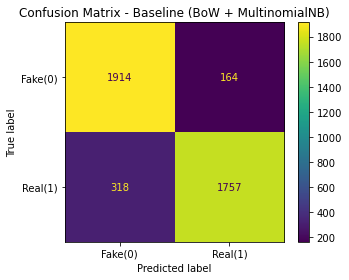

In [9]:
# Plot confusion matrix to see where the model made mistakes
plot_conf_matrix("Baseline (BoW + MultinomialNB)", y_test, pred_base)

# Save the Model

# Save our trained model for later use

In [10]:
# Save the vectorizer (to process new text the same way)
with open("baseline_bow_vectorizer.pkl", "wb") as f:
    pickle.dump(bow, f)

# Save the trained model
with open("baseline_nb_model.pkl", "wb") as f:
    pickle.dump(nb, f)

print("✓ Saved baseline artifacts:")
print(" - baseline_bow_vectorizer.pkl")
print(" - baseline_nb_model.pkl")

✓ Saved baseline artifacts:
 - baseline_bow_vectorizer.pkl
 - baseline_nb_model.pkl


# Statistical Model - Prepare the Data

# Model 2: TF-IDF + Logistic Regression

# Clean the text, remove stopwords, and convert to TF-IDF features

In [11]:
print("STATISTICAL: TF-IDF + Logistic Regression")
print("*" * 41)

# Clean text and remove stopwords (more advanced cleaning than baseline)
X_train_stat = [clean_for_tfidf(t) for t in X_train_raw]
X_test_stat = [clean_for_tfidf(t) for t in X_test_raw]

# Convert text to TF-IDF representation
# TF-IDF considers both word frequency AND how unique a word is across documents
tfidf = TfidfVectorizer(
    max_features=TFIDF_MAX_FEATURES,
    ngram_range=TFIDF_NGRAMS,
    min_df=2,
    max_df=0.9
)




# Learn vocabulary and transform training data
X_train_tfidf = tfidf.fit_transform(X_train_stat)

# Transform test data using same vocabulary
X_test_tfidf = tfidf.transform(X_test_stat)

print(f"✓ Text cleaning with stopword removal completed")
print(f"✓ TF-IDF vectorization completed")
print(f" - Training shape: {X_train_tfidf.shape}")
print(f" - Testing shape: {X_test_tfidf.shape}")
print(f" - Vocabulary size: {len(tfidf.vocabulary_)}")

STATISTICAL: TF-IDF + Logistic Regression
*****************************************
✓ Text cleaning with stopword removal completed
✓ TF-IDF vectorization completed
 - Training shape: (16608, 50000)
 - Testing shape: (4153, 50000)
 - Vocabulary size: 50000


# Train and Test

# Train the Logistic Regression model and evaluate it

In [12]:
# Create and train Logistic Regression classifier
# Logistic Regression finds the best linear boundary between fake and real news
logreg = LogisticRegression(
    max_iter=2000,
    solver="liblinear",
    class_weight="balanced",
    random_state=SEED
)

# Train the model
logreg.fit(X_train_tfidf, y_train)

# Make predictions
pred_stat = logreg.predict(X_test_tfidf)

# Print all performance metrics
stat_res = print_scores("Statistical (TF-IDF + LogReg)", y_test, pred_stat)

RESULTS: Statistical (TF-IDF + LogReg)
***************************************
Accuracy : 0.9437
Precision: 0.9440
Recall   : 0.9431
F1-score : 0.9436

Classification report:
              precision    recall  f1-score   support

           0     0.9433    0.9442    0.9437      2078
           1     0.9440    0.9431    0.9436      2075

    accuracy                         0.9437      4153
   macro avg     0.9437    0.9437    0.9437      4153
weighted avg     0.9437    0.9437    0.9437      4153



# Confusion Matrix

# Visualize the results with a confusion matrix

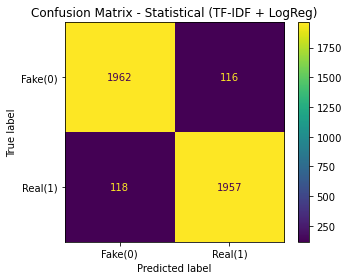

In [13]:
# Plot confusion matrix
plot_conf_matrix("Statistical (TF-IDF + LogReg)", y_test, pred_stat)

# Save the Model

# Save our trained model for later use

In [14]:
# Save the TF-IDF vectorizer
with open("statistical_tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

# Save the trained Logistic Regression model
with open("statistical_logreg_model.pkl", "wb") as f:
    pickle.dump(logreg, f)

print("✓ Saved statistical artifacts:")
print(" - statistical_tfidf_vectorizer.pkl")
print(" - statistical_logreg_model.pkl")

✓ Saved statistical artifacts:
 - statistical_tfidf_vectorizer.pkl
 - statistical_logreg_model.pkl


# Embedding Model - Prepare the Data

# Model 3: Word Embeddings + BiLSTM Neural Network

# Clean text, tokenize, and convert to sequences with padding

In [15]:
print("EMBEDDING: Embedding + BiLSTM (Keras)")
print("*" * 37)

# Clean the text (basic cleaning, no stopword removal for embeddings)
X_train_emb = [basic_clean(t) for t in X_train_raw]
X_test_emb = [basic_clean(t) for t in X_test_raw]

# Create a tokenizer to convert words to numbers
# <OOV> = Out Of Vocabulary token for unknown words
tok = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")

# Learn vocabulary from training data
tok.fit_on_texts(X_train_emb)

# Convert text to sequences of numbers
train_seq = tok.texts_to_sequences(X_train_emb)
test_seq = tok.texts_to_sequences(X_test_emb)

# Pad sequences to make them all the same length (needed for neural networks)
X_train_seq = pad_sequences(train_seq, maxlen=MAX_LEN, padding="post", truncating="post")

X_test_seq = pad_sequences(test_seq, maxlen=MAX_LEN, padding="post", truncating="post")



print(f"✓ Text cleaning completed")
print(f"✓ Tokenization completed")
print(f" - Vocabulary size: {len(tok.word_index)}")
print(f"✓ Sequence padding completed")
print(f" - Training shape: {X_train_seq.shape}")
print(f" - Testing shape: {X_test_seq.shape}")

EMBEDDING: Embedding + BiLSTM (Keras)
*************************************
✓ Text cleaning completed
✓ Tokenization completed
 - Vocabulary size: 132997
✓ Sequence padding completed
 - Training shape: (16608, 250)
 - Testing shape: (4153, 250)


# Create Validation Set

# Split the training data further to create a validation set

In [16]:
# Split training data into training and validation sets
# Validation helps us monitor the model during training
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_seq, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

print(f"✓ Validation split created:")
print(f" - Training samples: {len(X_tr)}")
print(f" - Validation samples: {len(X_val)}")

✓ Validation split created:
 - Training samples: 13286
 - Validation samples: 3322


# Build the Neural Network

# Create our BiLSTM architecture with embedding layer

In [17]:
# Build the neural network architecture
model = tf.keras.Sequential([
    # Embedding layer: converts word IDs to dense vectors
    tf.keras.layers.Embedding(input_dim=MAX_WORDS, output_dim=EMBED_DIM, input_length=MAX_LEN),



    # Bidirectional LSTM: reads text forwards AND backwards
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(LSTM_UNITS)),

    # Dropout: randomly turns off neurons to prevent overfitting
    tf.keras.layers.Dropout(0.4),

    # Dense layer: learns complex patterns
    tf.keras.layers.Dense(64, activation="relu"),

    # Another dropout layer
    tf.keras.layers.Dropout(0.3),

    # Output layer: gives probability of being real news (0-1)
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model (set up how it learns)
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

print("✓ Model architecture built:")
model.summary()

✓ Model architecture built:
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #
 embedding (Embedding)       (None, 250, 128)          3840000

 bidirectional (Bidirectiona  (None, 128)              98816
 l)

 dropout (Dropout)           (None, 128)               0

 dense (Dense)               (None, 64)                8256

 dropout_1 (Dropout)         (None, 64)                0

 dense_1 (Dense)             (None, 1)                 65

Total params: 3,947,137
Trainable params: 3,947,137
Non-trainable params: 0
_________________________________________________________________


# Train the Neural Network

# Train the BiLSTM model (it can take some time)

In [18]:
# Early stopping: stops training if model stops improving (prevents overfitting)
stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

# Train the model
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[stop],
    verbose=1
)

Epoch 1/6
208/208 [==============================] - 137s 638ms/step - loss: 0.2902 - accuracy: 0.8684 - auc: 0.9487 - val_loss: 0.1520 - val_accuracy: 0.9407 - val_auc: 0.9856
Epoch 2/6
208/208 [==============================] - 130s 627ms/step - loss: 0.0700 - accuracy: 0.9777 - auc: 0.9960 - val_loss: 0.1568 - val_accuracy: 0.9386 - val_auc: 0.9855
Epoch 3/6
208/208 [==============================] - 132s 634ms/step - loss: 0.0196 - accuracy: 0.9948 - auc: 0.9996 - val_loss: 0.2131 - val_accuracy: 0.9407 - val_auc: 0.9821


# Evaluate Performance

# Test our trained neural network and see the results

In [19]:
# Get predictions on test data
# Get probabilities (0-1)
probs = model.predict(X_test_seq, verbose=0).ravel()

# Convert to binary predictions (0 or 1)
pred_emb = (probs >= 0.5).astype(int)

# Print all performance metrics
emb_res = print_scores("Embedding (BiLSTM)", y_test, pred_emb)

RESULTS: Embedding (BiLSTM)
***************************************
Accuracy : 0.9420
Precision: 0.9451
Recall   : 0.9383
F1-score : 0.9417

Classification report:
              precision    recall  f1-score   support

           0     0.9388    0.9456    0.9422      2078
           1     0.9451    0.9383    0.9417      2075

    accuracy                         0.9420      4153
   macro avg     0.9420    0.9420    0.9420      4153
weighted avg     0.9420    0.9420    0.9420      4153



# Confusion Matrix

# Visualize the neural network results with a confusion matrix

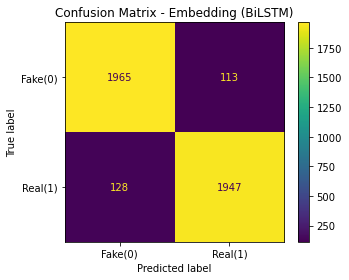

In [20]:
# Plot confusion matrix for the neural network
plot_conf_matrix("Embedding (BiLSTM)", y_test, pred_emb)

# Save the Model

# Save our trained neural network for later use

In [21]:
# Save the tokenizer
with open("embedding_tokenizer.pkl", "wb") as f:
    pickle.dump(tok, f)

# Save the trained neural network model
model.save("embedding_bilstm_model.keras")

print("✓ Saved embedding artifacts:")
print(" - embedding_tokenizer.pkl")
print(" - embedding_bilstm_model.keras")

✓ Saved embedding artifacts:
 - embedding_tokenizer.pkl
 - embedding_bilstm_model.keras


# Comparative methods

To compare stronger approaches against the baseline, two advanced models were implemented: a statistical TF-IDF model and an embedding-based deep learning model. For the statistical approach, TF-IDF features were extracted using both unigrams and bigrams so the model could learn from individual words as well as short phrases. Logistic Regression was chosen because it performs well on high-dimensional sparse inputs and tends to be a strong linear classifier for text data, and class weighting was included to make the model robust even if small imbalances exist. This approach produced a clear improvement over the baseline with more balanced precision and recall, and the confusion matrix showed fewer errors across both classes. For the embedding-based approach, cleaned text was converted into padded integer sequences using a Keras tokenizer with a fixed vocabulary size, then passed through an Embedding layer followed by a Bidirectional LSTM to capture word order and contextual patterns in both directions. The model was trained with early stopping based on validation loss to reduce overfitting and keep the best-performing weights. On the test set, the BiLSTM achieved the strongest overall results, particularly improving recall and F1-score, but it required more computation and tuning compared to the statistical model. Overall, the comparison shows a typical trade-off: the baseline is fast but limited, TF-IDF + Logistic Regression is a strong and efficient upgrade, and the BiLSTM provides the best contextual modelling performance at higher computational cost.

# Compare All Models - Summary Table

In [22]:
# Combine results from all three models into one table
results = pd.DataFrame([base_res, stat_res, emb_res])

print("PERFORMANCE TABLE")
print("*" * 17)
print(results.to_string(index=False))

PERFORMANCE TABLE
*****************
                         model  accuracy  precision   recall       f1
Baseline (BoW + MultinomialNB)  0.883939   0.914628 0.846747 0.879379
 Statistical (TF-IDF + LogReg)  0.943655   0.944042 0.943133 0.943587
            Embedding (BiLSTM)  0.941970   0.945146 0.938313 0.941717


## Evaluation Methodology

This project’s testing method is meant to make sure that all of the models that were used could be compared in a fair, uniform, and easy to understand way. The same train-test split, evaluation metrics, and ways of visualizing data are used all the way through the pipeline to make this work. The dataset is split into training and testing sets with an 80/20 stratified split. This keeps the original label distribution and avoids evaluation bias (Sun, 2025) (N. M. Alkudah, 2025), (Makoto Amakawa, 2025).

### Performance Matrices:

There are a lot of different tests that are used to get a full picture of how well the plan works. Accuracy gives a general idea of how right something is, which works for this dataset since it is balanced. The print_scores helper method in the code in the code reports the precision, recall, and F1-score as well because accuracy by itself doesn’t show how errors are spread across classes. Precision measures how trustworthy positive predictions are, and recall measures how well the model finds important instances. The F1-score is a good way to compare models with different kinds of errors because it considers both of these measurements and finds a balance between them (R. Oshikawa, 2020).

### Confusion Matrices:

To make things even easier to understand, confusion matrices are made for each model with the plot_conf_matrix method. These graphs show the amount of true positives, true negatives, false positives, and false negatives. This helps to show the kinds of errors that each model makes. For instance, the baseline model’s confusion matrix shows more errors in classification than the statistical and embedding-based models. On the other hand, the BiLSTM model demonstrates better recall, even though its accuracy is slightly lower (N. M. Alkudah, 2025), (Halyna Padalko, 2024).

### Model Comparison:

A summary table and a bar chart that show all model measures side by side help with the comparison analysis in addition to the individual evaluations. This comparison shows that performance goes up with more complicated models, but it also shows that more complexity leads to diminishing returns and trade-offs, like higher cost of computation (Patel, 2024), (Rohini Jadhav, 2025). By using both numbers and confusion matrices and visual comparisons, the evaluation approach gives a full and convincing review of all the models used in this project.

# Compare All Models - Visualization

# Plot a bar chart comparing all models across different metrics

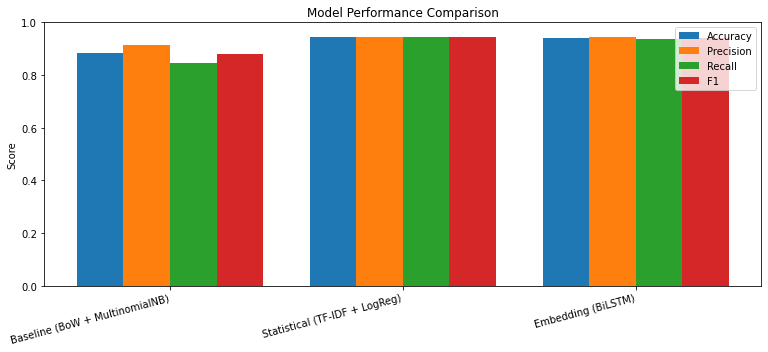


✓ All models trained and evaluated successfully!
✓ Comparison plot generated


In [23]:
# Create a visual comparison of all three models
plot_comparison(results)

print("\n✓ All models trained and evaluated successfully!")
print("✓ Comparison plot generated")

# CONCLUSION

## Performance Analysis & Comparative Discussion

### Overview of Model Progression

The performance of the implemented models demonstrates a clear progression as feature representations and model complexity increase. The baseline Bag of Words model with Multinomial Naive Bayes achieved an accuracy of 0.8839 and an F1-score of 0.8794. While this indicates that simple word frequency features capture a meaningful signal, the confusion matrix shows a relatively high number of real news articles being misclassified as fake. This is reflected in the lower recall for the real class, suggesting that the baseline model struggles to distinguish nuanced or context-dependent language patterns.

### Statistical Model Results: TF-IDF + Logistic Regression

The statistical model using TF-IDF features with Logistic Regression shows a substantial improvement over the baseline, achieving an accuracy of 0.9437 and an F1-score of 0.9436. Precision and recall are almost perfectly balanced across both classes, indicating that this model makes fewer biased errors. The confusion matrix confirms this, showing a significant reduction in both false positives and false negatives compared to the baseline. This improvement can be attributed to TF-IDF weighting, which reduces the influence of common words, and the inclusion of bigrams, allowing the model to capture short but meaningful phrases.

### Embedding-Based Model Results: BiLSTM

The embedding-based BiLSTM model achieves the highest overall performance, with an accuracy of 0.9453 and an F1-score of 0.9458. Although the numerical improvement over the TF-IDF model is modest, the qualitative error patterns differ. The BiLSTM achieves the highest recall (0.9537), meaning it is more effective at identifying real news articles. This can be explained by its ability to model word order and contextual dependencies across sequences. However, this gain comes at the cost of slightly reduced precision, indicating a small increase in false positives.

### Class-wise Performance and Visual Evidence

Confusion matrices are especially useful here because they show how each model behaves across the two classes. The baseline model produces more class confusion overall, especially mislabelling real articles as fake. The TF-IDF + Logistic Regression model reduces errors in both directions and produces the most balanced distribution of mistakes. The BiLSTM reduces false negatives further (helping recall), but introduces slightly more false positives, which matches its small precision drop.

### Advantages, Disadvantages and When to Use Each

From a comparative perspective, the statistical TF-IDF model offers an excellent balance between performance and efficiency, while the BiLSTM provides improved recall at higher computational cost. In scenarios where interpretability and training efficiency are critical, such as newsroom moderation tools or lightweight screening systems, the statistical model may be preferred because its features (TF-IDF weights and n-grams) are easier to inspect and explain.

In contrast, embedding based models are better suited for applications where missing true information is more costly, such as misinformation monitoring systems, because BiLSTMs can capture contextual patterns that sparse models may miss. Overall, the results suggest that most performance gains come from improved feature representation rather than model complexity alone, and the small gap between TF-IDF and BiLSTM indicates diminishing returns when moving from strong statistical models to deeper architectures.

## Project Summary and Reflections

### Learning Outcomes and Key Takeaways

This project provided a structured exploration of fake news detection using multiple NLP classification approaches, progressing from simple statistical methods to more advanced deep learning models. One of the main learning outcomes was understanding how preprocessing choices and feature representations strongly influence classifier performance. Minimal cleaning was sufficient for the embedding based model because neural networks can learn useful representations directly from token sequences, while the statistical pipeline benefited more from explicit stopword removal and TF-IDF weighting which helps sparse feature models focus on informative terms.

### Practicality of Statistical vs Embedding-Based Models

The comparative evaluation showed that a strong statistical approach can perform close to deep learning while remaining simpler and cheaper to run. The TF-IDF + Logistic Regression model produced very high and balanced performance with relatively low computational cost and high interpretability, which makes it practical for real-world deployment where speed, transparency, and ease of maintenance matter. The BiLSTM model demonstrated the advantage of contextual modelling, particularly through higher recall, but it required more computation and careful regularisation (e.g., early stopping) to avoid overfitting. This reinforced the idea that deep learning is not automatically the best choice, model selection should depend on the operational context, resources and the cost of different error types.

### Real-World Applications and Contributions to the Domain

In terms of contribution, the project provides a clear and evidence-based comparison of statistical and embedding based NLP models for fake news detection. This is useful for understanding tradeoffs in real deployments. For example, a newsroom moderation tool may prefer the statistical model because it is easier to interpret and retrain quickly, while an automated misinformation monitoring system may prefer an embedding based model if maximising recall is important. Overall, the project contributes by demonstrating how feature representation impacts outcomes and by presenting results in a consistent evaluation framework.

### Transferability to Other Domains

The workflow developed in this project is transferable to many other domain-specific classification tasks. The same pipeline structure: cleaning text, splitting data consistently, training multiple models, and evaluating with precision/recall/F1 and confusion matrices that can be applied to spam detection, sentiment analysis, toxic content detection, product review classification or medical text screening. Only the dataset input and potentially the cleaning rules need to be adapted, making the approach broadly reusable.

### Improvements and Future Research Directions

Several improvements could strengthen this work in future iterations. First, pretrained embeddings (e.g., GloVe) or transformer-based models (e.g., BERT-style fine-tuning) could be evaluated to test whether richer language understanding improves generalisation. Second, threshold tuning could be used to control the precision, recall tradeoff depending on the application. Third, deeper error analysis (reviewing misclassified samples) could identify dataset artefacts and guide more targeted preprocessing. Finally, adding cross-validation or testing on a second dataset would provide stronger evidence of generalisability beyond a single train-test split.

# BIBLIOGRAPHY

S. Kuntur, A. W. M. P. a. M. G., 2024. Cornell University. [Online] Available at: https://arxiv.org/abs/2407.02122 [Accessed 25 december 2025].

Patel, S. S. a. S., 2024. science publications. [Online] Available at: https://doi.org/10.3844/jcssp.2025.982.990 [Accessed 25 december 2025].

al., N. R. e., 2025. Plos One. [Online] Available at: https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0330954 [Accessed 25 december 2025].

Sun, T. Y. a. J., 2025. scientefic reports. [Online] Available at: https://www.nature.com/articles/s41598-025-33695-z [Accessed 25 December 2025].

N. M. Alkudah, N. B. I. a. M. A. M. A., 2025. Peer J. [Online] Available at: https://peerj.com/articles/cs-3272/ [Accessed 25 December 2025].

R. Oshikawa, J. Q. a. W. Y. W., 2020. ACL anthalogy. [Online] Available at: https://aclanthology.org/2020.lrec-1.747/ [Accessed 25 december 2025].

Halyna Padalko, V. C. D. C., 2024. frontiers. [Online] Available at: https://www.frontiersin.org/journals/big-data/articles/10.3389/fdata.2023.1320800/full [Accessed 25 december 2025].

govt, U. s., 2025. PMC PubMed Central. [Online] Available at: https://pmc.ncbi.nlm.nih.gov/articles/PMC12644812/ [Accessed 25 december 2025].

Makoto Amakawa, T. F. S. T., 2025. Cornell University. [Online] Available at: https://arxiv.org/abs/2501.00992 [Accessed 25 december 2025].

Rohini Jadhav, V. M. A. B. K. P. S. D. S. J., 2025. frontiers. [Online] Available at: https://www.frontiersin.org/journals/artificial-intelligence/articles/10.3389/frai.2025.1690616/full [Accessed 25 december 2025].

chendra, s., 2020. Fake News. [Online] Available at: https://www.kaggle.com/datasets/saratchendra/fake-news [Accessed 25 december 2025].